# MSCA681 Tutorial 2: Data visualization with matplotlib and seaborn

Data visualization is an important part of exploring a dataset before building data mining models.

Visualizations can help us:
- understand numerical and categorical variables;
- identify unusual observations;
- compare groups;
- examine relationships between variables.

In this tutorial, we will focus on:
- Histograms
- Boxplots
- Bar charts
- Scatterplots
- Correlation heatmaps

We will mainly use Seaborn to create plots and Matplotlib to add titles and labels.

* matplotlib is an open-source python library for visualization.
* Seaborn is a Python visualization library based on matplotlib. It provides a high-level interface for drawing attractive statistical graphics. **Visit website for more**.
* How to install:
    * conda install matplotlib (if you do not have conda then you can use pip instead)
    * conda install seaborn



In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

Matplotlib is building the font cache; this may take a moment.


### Loading the dataset: Tips

In [2]:
tips = sns.load_dataset("tips")

## Exploring the Dataset

Before creating visualizations, we should first become familiar with the dataset.

*head()* displays the first five rows of the dataset.

In [3]:
tips.head() # Can specify how many by putting number in the 
            # parentheses.

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [4]:
tips.tail(10)

,total_bill,tip,sex,smoker,day,time,size
234,15.53,3.00,Male,Yes,Sat,Dinner,2
235,10.07,1.25,Male,No,Sat,Dinner,2
236,12.60,1.00,Male,Yes,Sat,Dinner,2
237,32.83,1.17,Male,Yes,Sat,Dinner,2
238,35.83,4.67,Female,No,Sat,Dinner,3
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2
243,18.78,3.00,Female,No,Thur,Dinner,2


*shape* returns the number of rows and columns in the dataset.

The first number represents the number of observations, and the second represents the number of variables.

In [5]:
tips.shape

(244, 7)

In [6]:
tips.columns

Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='object')

*info()* provides information about:

- variable names
- data types
- the number of non-missing values
- the size of the dataset

In [7]:
tips.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


*describe()* provides summary statistics for numerical variables, including:

- count
- mean
- standard deviation
- minimum
- quartiles
- maximum

In [8]:
tips.describe()

,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


*isnull().sum()* counts the number of missing values in each variable.

A value of 0 means that no missing values were found in that variable.

In [9]:
tips.isnull().sum()

total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

**value_counts()** shows how many observations belong to each category.

This is useful for understanding categorical variables before creating graphs.

In [10]:
tips["day"].value_counts()

day
Sat     87
Sun     76
Thur    62
Fri     19
Name: count, dtype: int64

In [11]:
tips["smoker"].value_counts()

smoker
No     151
Yes     93
Name: count, dtype: int64

**nunique()** shows the number of *unique* values in each variable.

In [12]:
tips.nunique()

total_bill    229
tip           123
sex             2
smoker          2
day             4
time            2
size            6
dtype: int64

## Histogram

Histogram are used to visualize the distribution of numerical variables.

The values are divided into intervals called bins. The height of each bar shows how many observations exist within that interval.

For example, we can examine the distribution of customers' total bills.

**TIP**: Type *TAB* on the 'hist' function and it shows you the sub-arguments you can use.

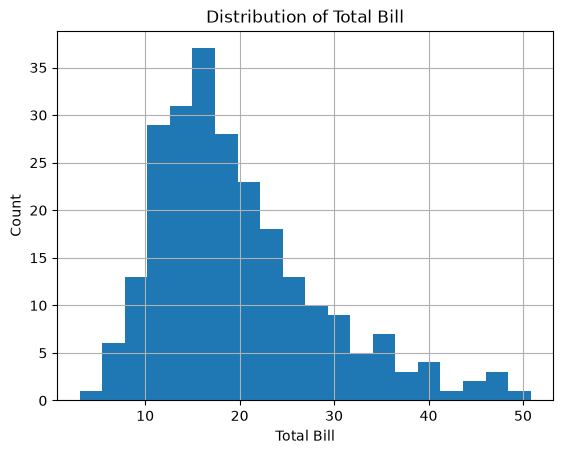

In [4]:
tips["total_bill"].hist(bins=20)

plt.title("Distribution of Total Bill")
plt.xlabel("Total Bill")
plt.ylabel("Count")

plt.show()

In [14]:
help(sns.histplot)

Help on function histplot in module seaborn.distributions:

histplot(data=None, *, x=None, y=None, hue=None, weights=None, stat='count', bins='auto', binwidth=None, binrange=None, discrete=None, cumulative=False, common_bins=True, common_norm=True, multiple='layer', element='bars', fill=True, shrink=1, kde=False, kde_kws=None, line_kws=None, thresh=0, pthresh=None, pmax=None, cbar=False, cbar_ax=None, cbar_kws=None, palette=None, hue_order=None, hue_norm=None, color=None, log_scale=None, legend=True, ax=None, **kwargs)
    Plot univariate or bivariate histograms to show distributions of datasets.

    A histogram is a classic visualization tool that represents the distribution
    of one or more variables by counting the number of observations that fall within
    discrete bins.

    This function can normalize the statistic computed within each bin to estimate
    frequency, density or probability mass, and it can add a smooth curve obtained
    using a kernel density estimate, simila

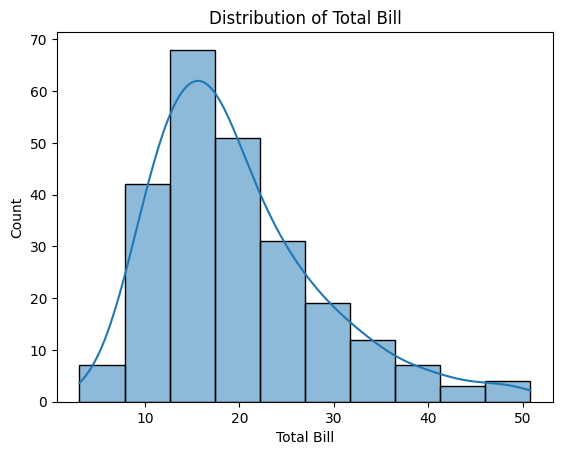

In [15]:
sns.histplot(data=tips, x="total_bill", bins=10, kde=True)

plt.title("Distribution of Total Bill")
plt.xlabel("Total Bill")
plt.ylabel("Count")

plt.show()

### How to interpret a histogram

When looking at a histogram, ask:

- Where are most observations located?
- What is the approximate range of the variable?
- Are there any very high or very low values?

### Skewness
Skewness describes whether a distribution is symmetric or has a longer tail on one side.

- Symmetric distribution: the left and right sides are approximately balanced.
- Positive (right) skew: the distribution has a longer tail toward larger values.
- Negative (left) skew: the distribution has a longer tail toward smaller values.

The direction of the skew is determined by the direction of the tail.

In a positively skewed distribution, very large values can pull the mean upward.

As a result, the mean is often greater than the median.

In [16]:
print("Mean:", tips["total_bill"].mean())
print("Median:", tips["total_bill"].median())

Mean: 19.78594262295082
Median: 17.795


### Another example

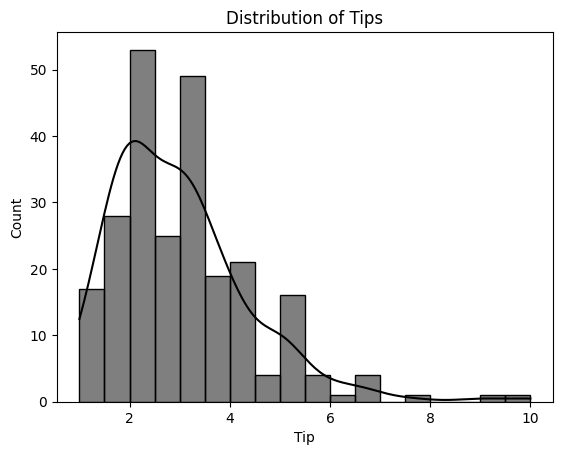

In [17]:
sns.histplot(data=tips, x="tip", bins='auto', color='black', kde=True)

plt.title("Distribution of Tips")
plt.xlabel("Tip")
plt.ylabel("Count")

plt.show()

## Boxplot

A boxplot is another way to examine numerical variables.

It provides a summary of the distribution and can help identify potential outliers.

The line inside the box represents the median.

Points beyond the whiskers may indicate potential outliers.

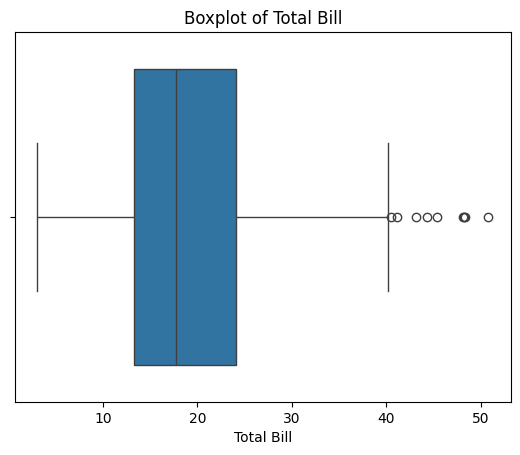

In [18]:
sns.boxplot(data=tips, x="total_bill")

plt.title("Boxplot of Total Bill")
plt.xlabel("Total Bill")

plt.show()

### How to interpret a boxplot

When looking at a boxplot, consider:

- Where is the median?
- How spread out are the observations?
- Are there any potential outliers?

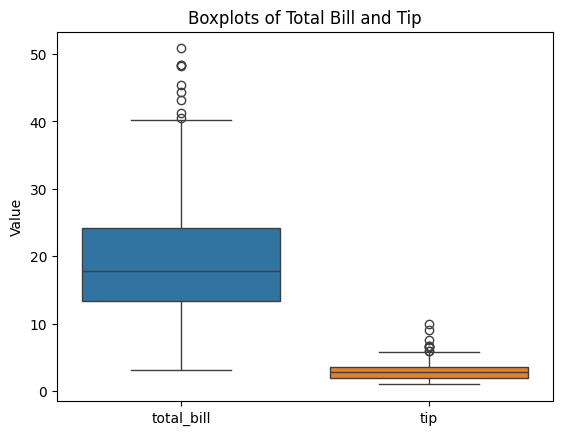

In [19]:
sns.boxplot(data=tips[["total_bill", "tip"]])

plt.title("Boxplots of Total Bill and Tip")
plt.ylabel("Value")

plt.show()

## Bar Chart

A bar chart is useful for visualizing categorical variables.

For example, we may want to know how many observations in the dataset belong to each day of the week.

Seaborn's *countplot()* automatically counts the number of observations in each category.

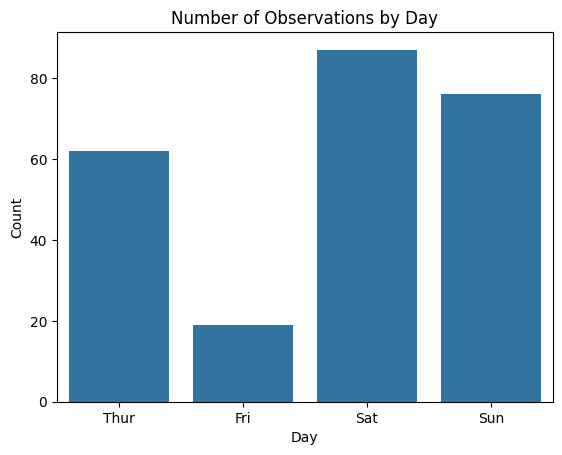

In [20]:
sns.countplot(data=tips, x="day")

plt.title("Number of Observations by Day")
plt.xlabel("Day")
plt.ylabel("Count")

plt.show()

### How to interpret a bar chart

The height of each bar represents the number of observations in that category.

When interpreting a bar chart, compare the heights of the bars to identify:

- the most common category
- the least common category
- differences in frequency across categories

**Remember:**

- Histogram --> numerical variable
- Bar chart --> categorical variable

### Bar Charts Can Also Summarize Numerical Variables

A bar chart can also be used to compare a numerical summary across categories.

In this example, each bar represents the average tip for a particular day.

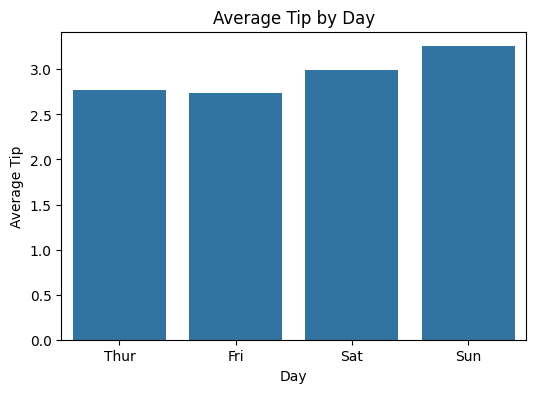

In [21]:
plt.figure(figsize=(6,4))

sns.barplot(data=tips, x="day", y="tip", estimator="mean", errorbar=None)

plt.title("Average Tip by Day")
plt.xlabel("Day")
plt.ylabel("Average Tip")

plt.show()

## Scatterplot

A scatterplot is used to examine the relationship between two numerical variables.

Each point represents one observation.

Here, we will examine whether the amount of the total bill is related to the amount of the tip.

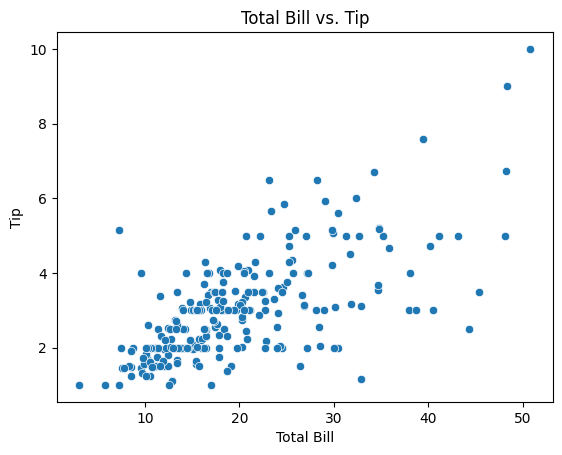

In [22]:
sns.scatterplot(data=tips, x="total_bill", y="tip")

plt.title("Total Bill vs. Tip")
plt.xlabel("Total Bill")
plt.ylabel("Tip")

plt.show()

### How to interpret a scatterplot

When looking at a scatterplot, consider:

- Do the two variables appear to be related?
- Do they tend to increase together?
- Does one tend to decrease as the other increases?
- Are there any unusual observations?

### Adding a Categorical Variable

The *hue* parameter allows us to use different colors for different categories.

Here, the points are separated according to whether the customer belongs to the smoker or non-smoker category.

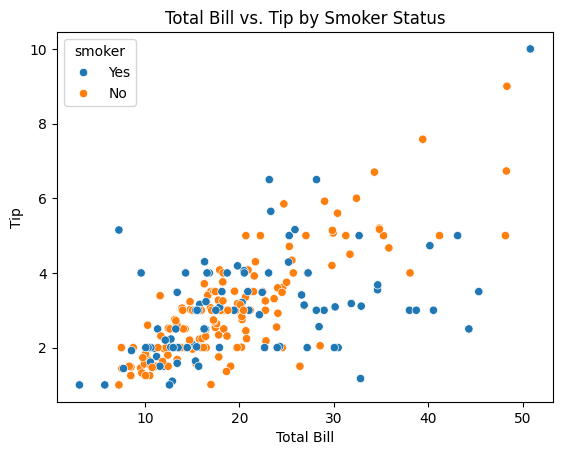

In [23]:
sns.scatterplot(
    data=tips,
    x="total_bill",
    y="tip",
    hue="smoker"
)

plt.title("Total Bill vs. Tip by Smoker Status")
plt.xlabel("Total Bill")
plt.ylabel("Tip")

plt.show()

## Correlation

Correlation measures the direction and strength of the linear relationship between numerical variables.

Correlation values range from -1 to +1:

- values closer to +1 indicate a stronger positive relationship
- values closer to -1 indicate a stronger negative relationship
- values closer to 0 indicate a weaker linear relationship.

In the tips dataset, we will use:
- total_bill
- tip
- size

The correlation matrix shows the correlation between every pair of numerical variables.

Notice that the diagonal values are all 1 because each variable is perfectly correlated with itself.

In [24]:
correlation = tips[["total_bill", "tip", "size"]].corr()

correlation

,total_bill,tip,size
total_bill,1.000000,0.675734,0.598315
tip,0.675734,1.000000,0.489299
size,0.598315,0.489299,1.000000


## Correlation Heatmap

A correlation heatmap provides a visual representation of the correlation matrix.

The number in each cell represents the correlation between two variables.

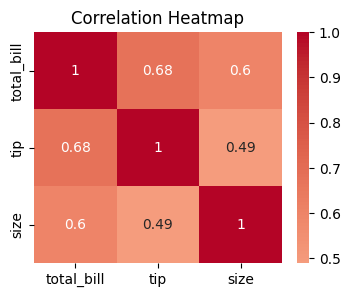

In [25]:
plt.figure(figsize=(4, 3))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")

plt.show()

### How to Interpret a Correlation Heatmap

When interpreting the heatmap, we look at the correlation values between different variables.

For example, compare the correlations between:

- total_bill and tip
- total_bill and size
- tip and size

# Example 2: Exploring another Dataset with more variables

So far, we created visualizations one at a time using the tips dataset.

With a dataset containing more variables, creating each graph separately can become repetitive.

In this example, we will use the Cereals dataset to learn how to:

- explore a larger dataset
- create subsets of numerical and categorical variables
- generate multiple histograms
- generate multiple boxplots
- generate multiple bar charts
- examine several relationships using scatterplots
- visualize correlations between numerical variables

In [26]:
cereals = pd.read_csv("Cereals.csv")

cereals.head()

,name,mfr,type,calories,protein,fat,sodium,fiber,carbo,sugars,potass,vitamins,shelf,weight,cups,rating
0,100%_Bran,N,C,70,4,1,130,10.0,5.0,6.0,280.0,25,3,1.0,0.33,68.402973
1,100%_Natural_Bran,Q,C,120,3,5,15,2.0,8.0,8.0,135.0,0,3,1.0,1.00,33.983679
2,All-Bran,K,C,70,4,1,260,9.0,7.0,5.0,320.0,25,3,1.0,0.33,59.425505
3,All-Bran_with_Extra_Fiber,K,C,50,4,0,140,14.0,8.0,0.0,330.0,25,3,1.0,0.50,93.704912
4,Almond_Delight,R,C,110,2,2,200,1.0,14.0,8.0,NaN,25,3,1.0,0.75,34.384843


## Explore the Dataset

Before creating visualizations, we first examine the structure of the dataset.

In [27]:
cereals.shape

(77, 16)

In [28]:
cereals.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   name      77 non-null     object 
 1   mfr       77 non-null     object 
 2   type      77 non-null     object 
 3   calories  77 non-null     int64  
 4   protein   77 non-null     int64  
 5   fat       77 non-null     int64  
 6   sodium    77 non-null     int64  
 7   fiber     77 non-null     float64
 8   carbo     76 non-null     float64
 9   sugars    76 non-null     float64
 10  potass    75 non-null     float64
 11  vitamins  77 non-null     int64  
 12  shelf     77 non-null     int64  
 13  weight    77 non-null     float64
 14  cups      77 non-null     float64
 15  rating    77 non-null     float64
dtypes: float64(7), int64(6), object(3)
memory usage: 9.8+ KB


In [29]:
cereals.describe()

,calories,protein,fat,sodium,fiber,carbo,sugars,potass,vitamins,shelf,weight,cups,rating
count,77.000000,77.000000,77.000000,77.000000,77.000000,76.000000,76.000000,75.000000,77.000000,77.000000,77.000000,77.000000,77.000000
mean,106.883117,2.545455,1.012987,159.675325,2.151948,14.802632,7.026316,98.666667,28.246753,2.207792,1.029610,0.821039,42.665705
std,19.484119,1.094790,1.006473,83.832295,2.383364,3.907326,4.378656,70.410636,22.342523,0.832524,0.150477,0.232716,14.047289
min,50.000000,1.000000,0.000000,0.000000,0.000000,5.000000,0.000000,15.000000,0.000000,1.000000,0.500000,0.250000,18.042851
25%,100.000000,2.000000,0.000000,130.000000,1.000000,12.000000,3.000000,42.500000,25.000000,1.000000,1.000000,0.670000,33.174094
50%,110.000000,3.000000,1.000000,180.000000,2.000000,14.500000,7.000000,90.000000,25.000000,2.000000,1.000000,0.750000,40.400208
75%,110.000000,3.000000,2.000000,210.000000,3.000000,17.000000,11.000000,120.000000,25.000000,3.000000,1.000000,1.000000,50.828392
max,160.000000,6.000000,5.000000,320.000000,14.000000,23.000000,15.000000,330.000000,100.000000,3.000000,1.500000,1.500000,93.704912


In [30]:
cereals.nunique()

name        77
mfr          7
type         2
calories    11
protein      6
fat          5
sodium      27
fiber       13
carbo       21
sugars      16
potass      35
vitamins     3
shelf        3
weight       7
cups        12
rating      77
dtype: int64

## Handling Missing Values

Before creating visualizations or building models, we should check if the dataset contains missing values.

One simple way to handle missing numerical values is to replace them with the median of that variable.

This process is called imputation.

In [31]:
cereals.isnull().sum()

name        0
mfr         0
type        0
calories    0
protein     0
fat         0
sodium      0
fiber       0
carbo       1
sugars      1
potass      2
vitamins    0
shelf       0
weight      0
cups        0
rating      0
dtype: int64

### Why do we use the median?

The median is less affected by unusually high or low values than the mean, so it is often a useful simple method for imputing numerical variables.

In [32]:
cereals["carbo"] = cereals["carbo"].fillna(cereals["carbo"].median())
cereals["sugars"] = cereals["sugars"].fillna(cereals["sugars"].median())
cereals["potass"] = cereals["potass"].fillna(cereals["potass"].median())

After imputation, we check the dataset again to make sure that the missing values have been handled.

In [33]:
cereals.isnull().sum()

name        0
mfr         0
type        0
calories    0
protein     0
fat         0
sodium      0
fiber       0
carbo       0
sugars      0
potass      0
vitamins    0
shelf       0
weight      0
cups        0
rating      0
dtype: int64

## Create Subsets of Variables

When a dataset contains many variables, it can be useful to group variables according to their type.

We will create:

- a subset containing numerical variables
- a subset containing categorical variables

This will make it easier to create several visualizations at the same time.

In [34]:
numerical_variables = cereals[
    ["calories", "protein", "fat", "sodium",
     "fiber", "carbo", "sugars", "potass",
     "weight", "cups", "rating"]
]

numerical_variables.head()

,calories,protein,fat,sodium,fiber,carbo,sugars,potass,weight,cups,rating
0,70,4,1,130,10.0,5.0,6.0,280.0,1.0,0.33,68.402973
1,120,3,5,15,2.0,8.0,8.0,135.0,1.0,1.00,33.983679
2,70,4,1,260,9.0,7.0,5.0,320.0,1.0,0.33,59.425505
3,50,4,0,140,14.0,8.0,0.0,330.0,1.0,0.50,93.704912
4,110,2,2,200,1.0,14.0,8.0,90.0,1.0,0.75,34.384843


In [35]:
categorical_variables = cereals[
    ["mfr", "type", "vitamins", "shelf"]
]

categorical_variables.head()

,mfr,type,vitamins,shelf
0,N,C,25,3
1,Q,C,0,3
2,K,C,25,3
3,K,C,25,3
4,R,C,25,3


Although vitamins and shelf are stored as numbers, they contain only a small number of possible values and are more useful here as categories.

For example, shelf identifies the shelf on which the cereal is displayed rather than measuring a continuous quantity.

## Multiple Histograms

Instead of creating a separate histogram for every numerical variable, pandas can generate histograms for several numerical variables in one command.

This allows us to quickly compare the distributions of several variables.

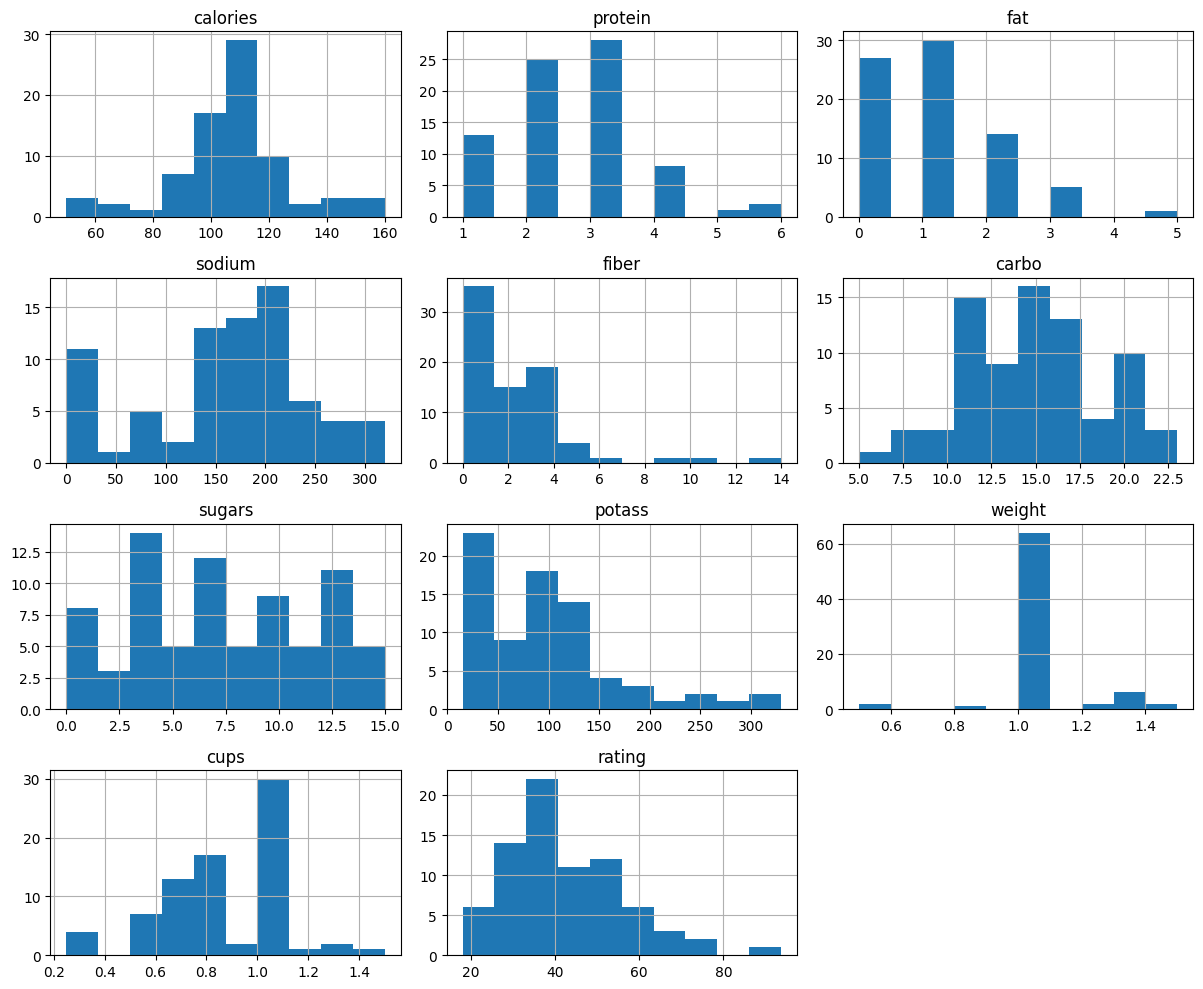

In [36]:
numerical_variables.hist(
    figsize=(12, 10),
    bins=10
)

plt.tight_layout()
plt.show()

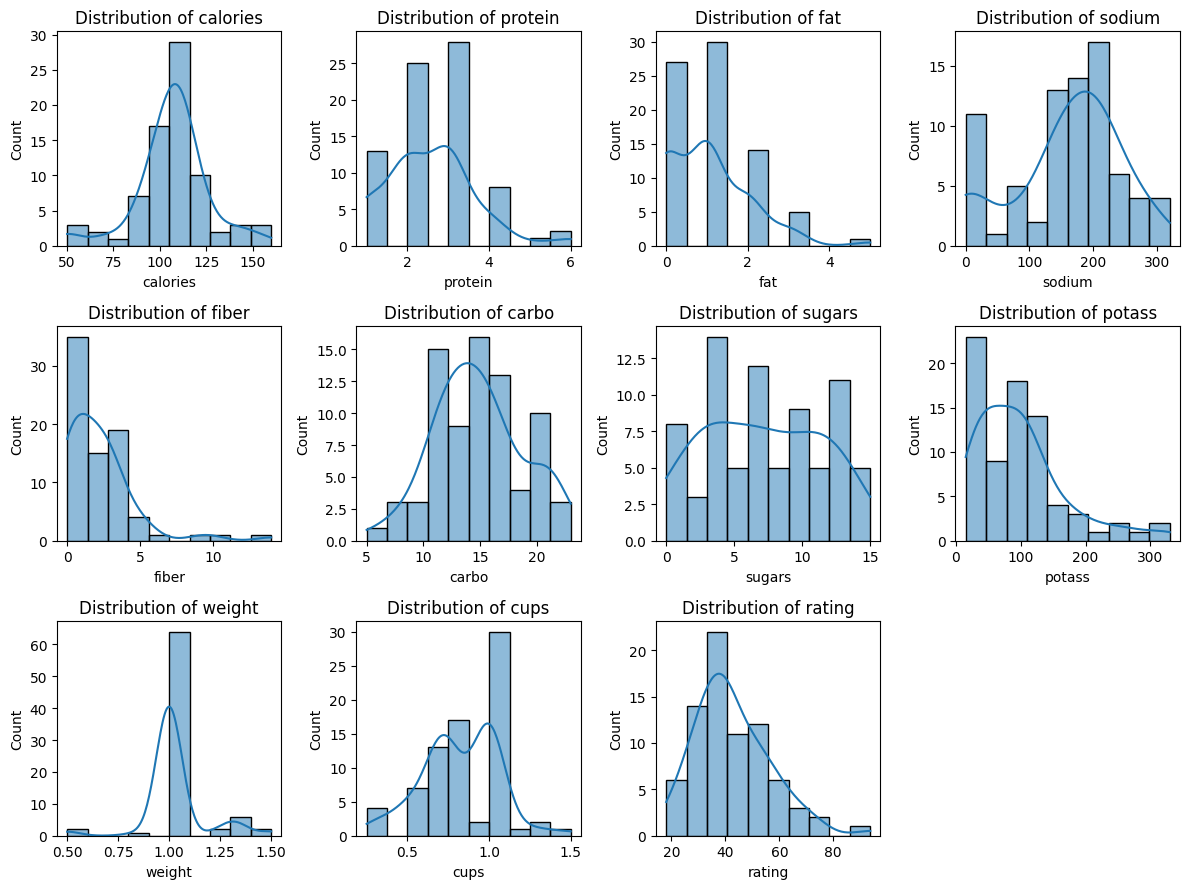

In [37]:
fig, axes = plt.subplots(3, 4, figsize=(12, 9))

axes = axes.flatten()

for plot, variable in zip(axes, numerical_variables.columns):
    sns.histplot(
        data=numerical_variables,
        x=variable,
        bins=10,
        kde=True,
        ax=plot
    )
    plot.set_title(f"Distribution of {variable}")

# Remove any unused subplot
for plot in axes[len(numerical_variables.columns):]:
    fig.delaxes(plot)

plt.tight_layout()
plt.show()

## Multiple Boxplots

We can also create several boxplots in one figure.

Using separate plots is useful when the numerical variables are measured on different scales.

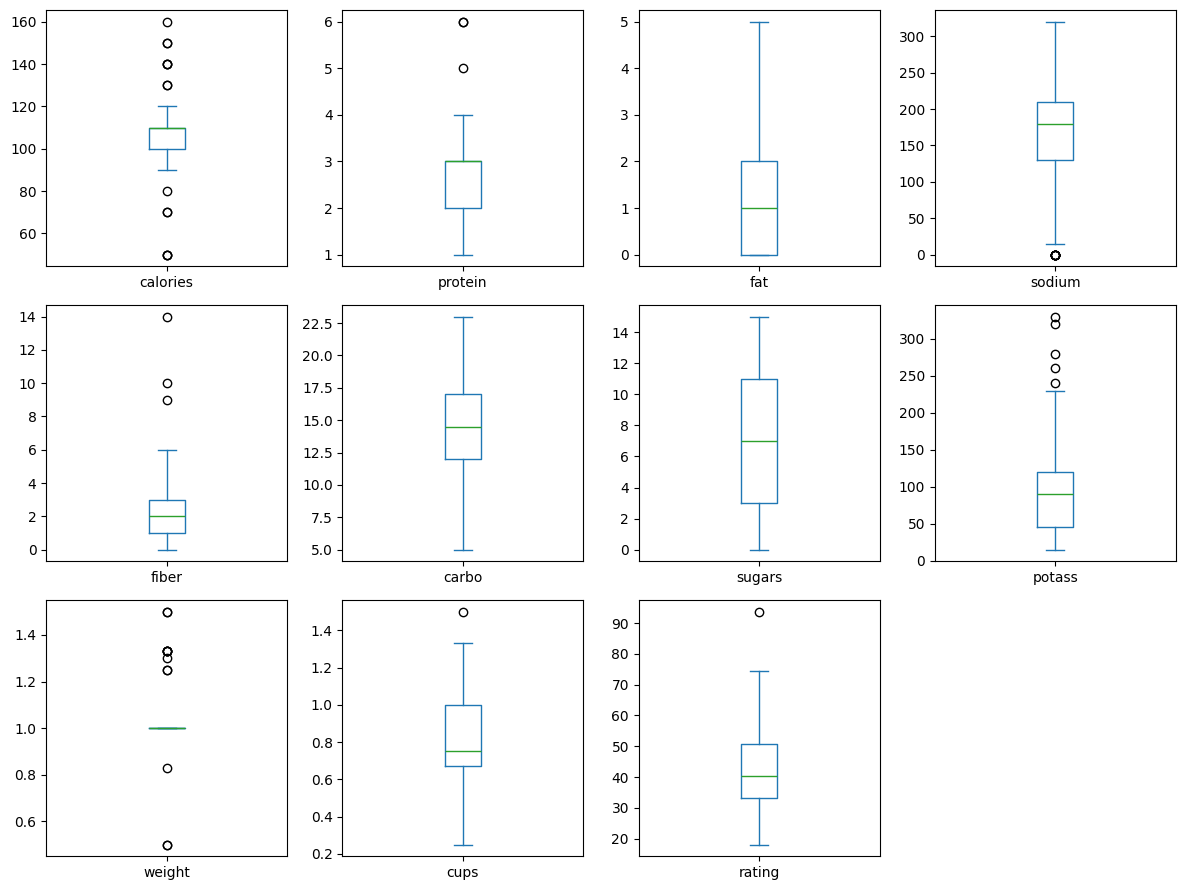

In [38]:
numerical_variables.plot(
    kind="box",
    subplots=True,
    layout=(3, 4),
    figsize=(12, 9)
)

plt.tight_layout()
plt.show()

## Multiple Bar Charts

For categorical variables, we can create a separate bar chart for each variable.

Instead of writing the same code repeatedly, we can use a loop.

A loop repeats the same plotting instructions for each variable in our categorical subset.

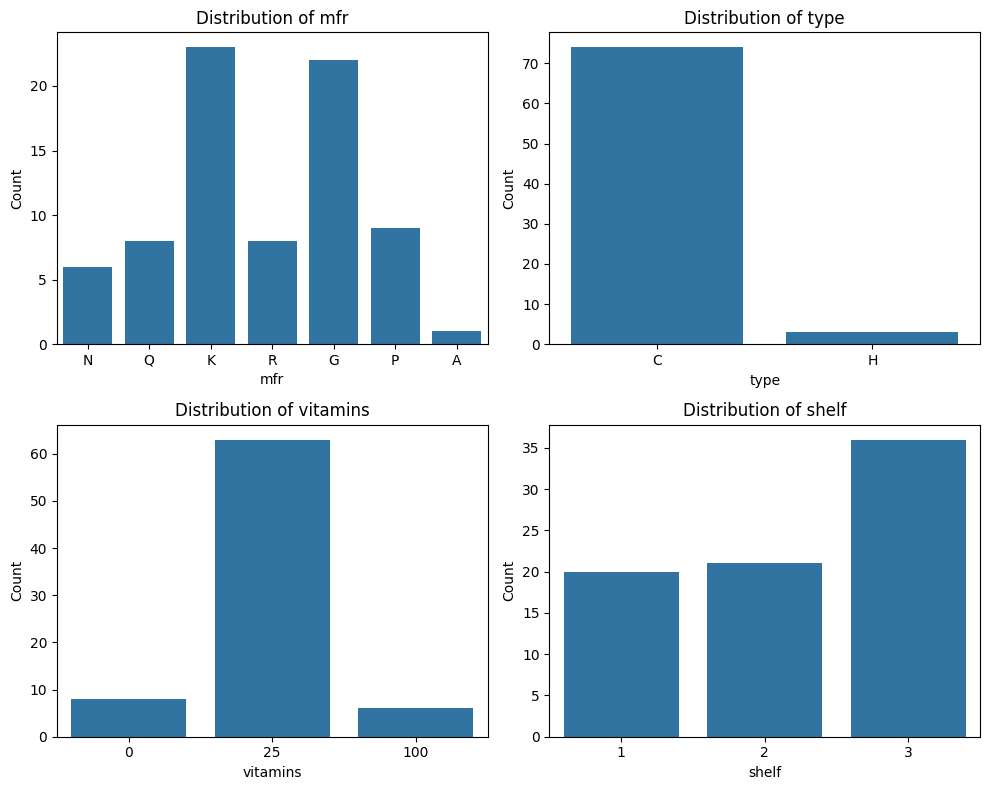

In [39]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

axes = axes.flatten()

for plot, variable in zip(axes, categorical_variables.columns):
    sns.countplot(data=cereals, x=variable, ax=plot)
    plot.set_title(f"Distribution of {variable}")
    plot.set_xlabel(variable)
    plot.set_ylabel("Count")

plt.tight_layout()
plt.show()

## Multiple Scatterplots

Scatterplots are useful for examining relationships between numerical variables.

In this example, we will examine how several nutritional variables are related to the cereal rating.

Because rating is our variable of interest, it will appear on the y-axis of each graph.

In [40]:
scatter_variables = [
    "calories",
    "protein",
    "fat",
    "fiber",
    "sugars"
]

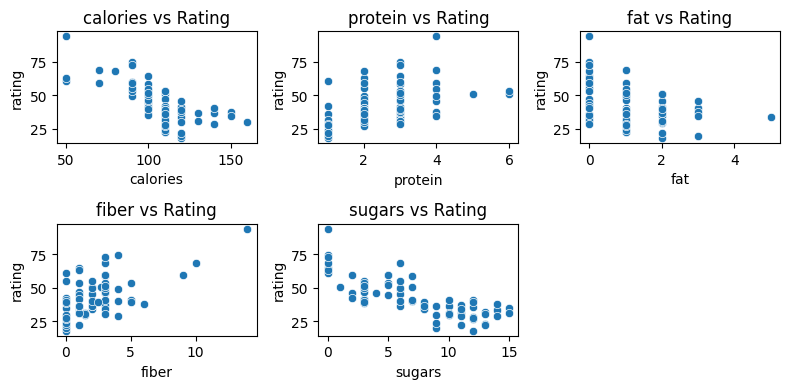

In [41]:
fig, axes = plt.subplots(2, 3, figsize=(8, 4))

axes = axes.flatten()

for plot, variable in zip(axes, scatter_variables):
    sns.scatterplot(
        data=cereals,
        x=variable,
        y="rating",
        ax=plot
    )

    plot.set_title(f"{variable} vs Rating")

# We can remove the unused plotting area
fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

Scatterplots are most useful when both variables are numerical and contain enough variation.

If a numerical variable has only a few possible values, the points may appear in vertical or horizontal groups, making the relationship harder to interpret.

Therefore, not every numerical variable is equally suitable for a scatterplot.

## Correlation Matrix

In [42]:
correlation = numerical_variables.corr()

correlation

,calories,protein,fat,sodium,fiber,carbo,sugars,potass,weight,cups,rating
calories,1.000000,0.019066,0.498610,0.300649,-0.293413,0.257776,0.566090,-0.071660,0.696091,0.087200,-0.689376
protein,0.019066,1.000000,0.208431,-0.054674,0.500330,-0.026459,-0.282084,0.562168,0.216158,-0.244469,0.470618
fat,0.498610,0.208431,1.000000,-0.005407,0.016719,-0.299068,0.300474,0.197826,0.214625,-0.175892,-0.409284
sodium,0.300649,-0.054674,-0.005407,1.000000,-0.070675,0.292342,0.057577,-0.041533,0.308576,0.119665,-0.401295
fiber,-0.293413,0.500330,0.016719,-0.070675,1.000000,-0.380444,-0.138729,0.910052,0.247226,-0.513061,0.584160
carbo,0.257776,-0.026459,-0.299068,0.292342,-0.380444,1.000000,-0.471159,-0.360923,0.138628,0.367078,0.087913
sugars,0.566090,-0.282084,0.300474,0.057577,-0.138729,-0.471159,1.000000,0.003618,0.455741,-0.048772,-0.762227
potass,-0.071660,0.562168,0.197826,-0.041533,0.910052,-0.360923,0.003618,1.000000,0.420275,-0.499995,0.406651
weight,0.696091,0.216158,0.214625,0.308576,0.247226,0.138628,0.455741,0.420275,1.000000,-0.199583,-0.298124
cups,0.087200,-0.244469,-0.175892,0.119665,-0.513061,0.367078,-0.048772,-0.499995,-0.199583,1.000000,-0.203160


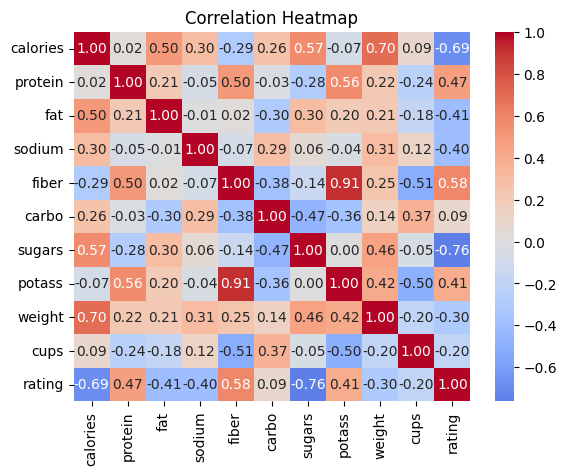

In [43]:
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

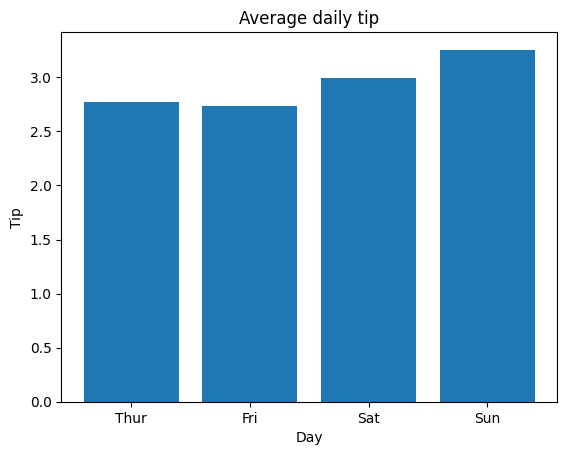

In [44]:
import matplotlib.pyplot as plt
import pandas as pd

data_path = "C:\\Users\\moeka\\OneDrive\\Documents\\DM\\dmba-datasets\\tips.csv" #Enter your file path
tips = pd.read_csv(data_path)

average_daily_tips = tips.groupby("day")["tip"].mean()

days = ["Thur", "Fri", "Sat", "Sun"]
daily_averages = [
    average_daily_tips["Thur"],
    average_daily_tips["Fri"],
    average_daily_tips["Sat"],
    average_daily_tips["Sun"],
]
plt.bar(x = days, height = daily_averages)

plt.title("Average daily tip")
plt.xlabel("Day")
plt.ylabel("Tip")
#plt.savefig("daily_tips.png")

plt.show()

* Seaborn has the three most common interfaces:
![alt text](Seaborn_functions-1.avif)

    * relplot():  These help you understand how pairs of variables in a dataset relate to each other. scatterplot(), lineplot()
    * displot(): These help you understand how variables in a dataset are distributed. 
    * catplot(): These also help you understand how pairs of variables in a dataset relate to each other. However, one of the variables usually contains discrete categories. Common examples of these include bar plots and box plots. 

    * You can also define each classification as either a figure-level or axes-level function. A figure-level function allows you to draw multiple subplots, with each showing a different category of data. In contrast, an axes-level function allows you to draw a single plot. 
    



In [45]:
import pandas as pd

data_path = "C:\\Users\\moeka\\OneDrive\\Documents\\DM\\dmba-datasets\\cycle_crossings_apr_oct_2017.csv" #Enter your file path
crossings = pd.read_csv(data_path)

print(crossings.head())

     Date        Day  High Temp (F)  Low Temp (F)  Precipitation  \
0  01-Apr   Saturday           46.0          37.0           0.00   
1  02-Apr     Sunday           62.1          41.0           0.00   
2  03-Apr     Monday           63.0          50.0           0.03   
3  04-Apr    Tuesday           51.1          46.0           1.18   
4  05-Apr  Wednesday           63.0          46.0           0.00   

  Brooklyn Bridge Manhattan Bridge Williamsburg Bridge Queensboro Bridge  \
0             606            1,446               1,915             1,430   
1           2,021            3,943               4,207             2,862   
2           2,470            4,988               5,178             3,689   
3             723            1,913               2,279             1,666   
4           2,807            5,276               5,711             4,197   

   Month  
0  April  
1  April  
2  April  
3  April  
4  April  


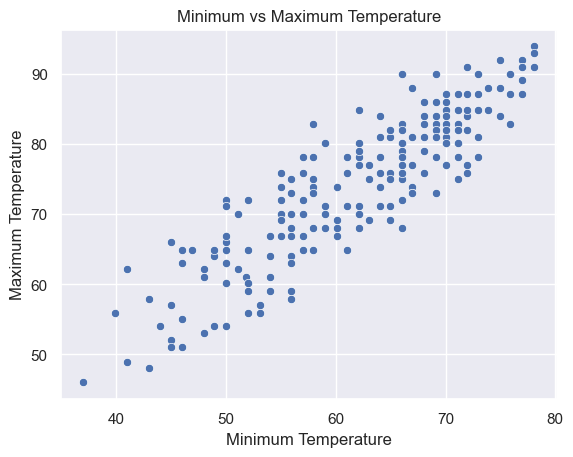

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="darkgrid")

(
    sns.scatterplot(
      data=crossings, x="Low Temp (F)", y="High Temp (F)"
      )
      .set(
          title="Minimum vs Maximum Temperature",
          xlabel="Minimum Temperature",
          ylabel="Maximum Temperature",
        )
)
plt.show()

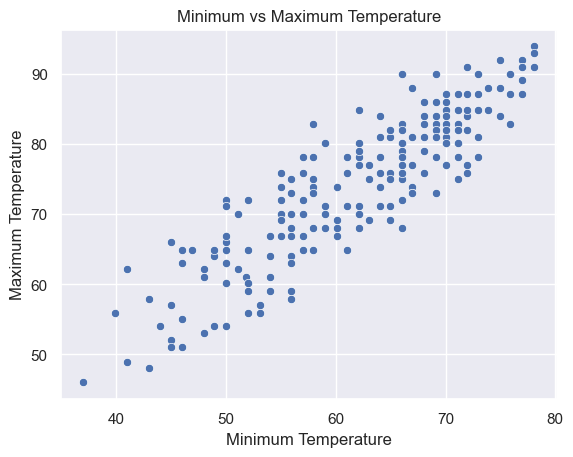

In [47]:
ax = sns.scatterplot(data=crossings, x="Low Temp (F)", y="High Temp (F)")
plt.title("Minimum vs Maximum Temperature")
plt.xlabel("Minimum Temperature")
plt.ylabel("Maximum Temperature")

plt.show()

In seaborn we can use `hue`, `size` and `style` parameters to add more dimensions to our visulaizations. This is called for instance `hue semantic`. 

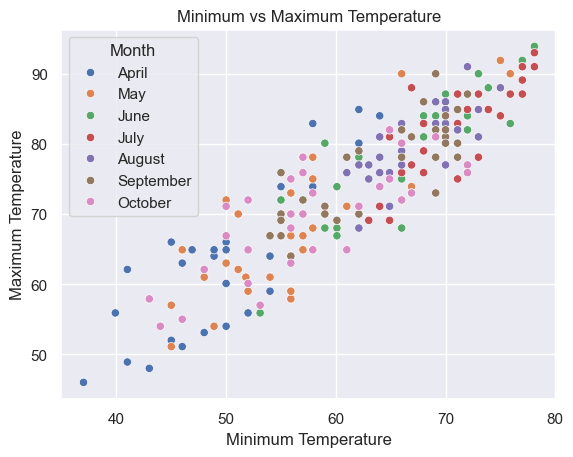

In [48]:
ax = sns.scatterplot(data = crossings, x ="Low Temp (F)", y = "High Temp (F)",
                      hue = 'Month')

plt.title("Minimum vs Maximum Temperature")
plt.xlabel("Minimum Temperature")
plt.ylabel("Maximum Temperature")

plt.show()

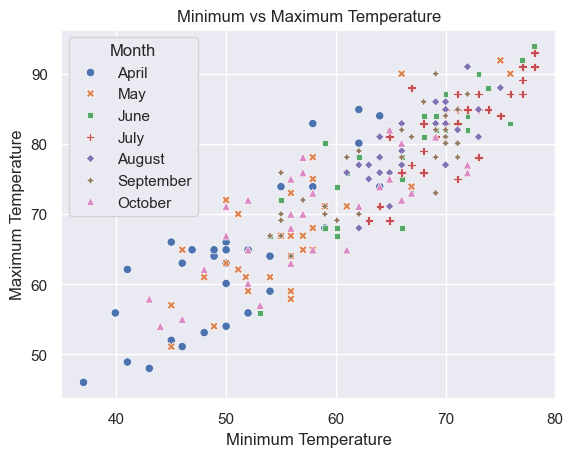

In [49]:
ax = sns.scatterplot(data = crossings, x ="Low Temp (F)", y = "High Temp (F)",
                      hue = "Month", style = "Month")

plt.title("Minimum vs Maximum Temperature")
plt.xlabel("Minimum Temperature")
plt.ylabel("Maximum Temperature")

plt.show()